# RiMEA 12c: Influence of Congestion

This notebook runs the three-room bottleneck scenario of RiMEA Test 12c (10 m, 10 m and 5 m rooms joined by two identical 1 m bottlenecks, 150 agents starting in room 1). RiMEA 4.1.1 sets no pass criterion; it asks to determine the number of agents in rooms 1 and 2 over time and the resulting flows in the bottlenecks.

The notebook:

- plots the geometry, trajectories, and both measurement lines
- plots the number of agents per room over time
- plots the cumulative crossings of both bottlenecks and reports the measured flows
- asserts only conservation of agents: room 1 + room 2 + room 3 + bottlenecks + evacuated = total at every frame

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:56 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pedpy

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "#f7f7f5",
        "axes.edgecolor": "#3a3a3a",
        "axes.labelcolor": "#1d1d1d",
        "axes.titleweight": "bold",
        "xtick.color": "#1d1d1d",
        "ytick.color": "#1d1d1d",
        "font.size": 11,
    }
)

SCENARIO_DIR = Path("scenario_files") / "Rimea-12c-congestion-influence.zip"
BOTTLENECK_LINES = [
    pedpy.MeasurementLine([(10.0, 4.5), (10.0, 5.5)]),
    pedpy.MeasurementLine([(20.2, 4.5), (20.2, 5.5)]),
]
GRID_SIZE = 0.25
FRAME_STEP = 10


## Load and Run the Scenario

In [4]:
%%capture
scenario = load_scenario(str(SCENARIO_DIR))
print(scenario.summary())

result = run_scenario(scenario, seed=42)
traj = pedpy.TrajectoryData(
    result.trajectory_dataframe()[["id", "frame", "x", "y"]].copy(),
    frame_rate=result.frame_rate,
)
walkable_area = pedpy.WalkableArea(scenario.walkable_polygon)
result.metrics

## Plot Geometry, Trajectories, and Measurement Lines

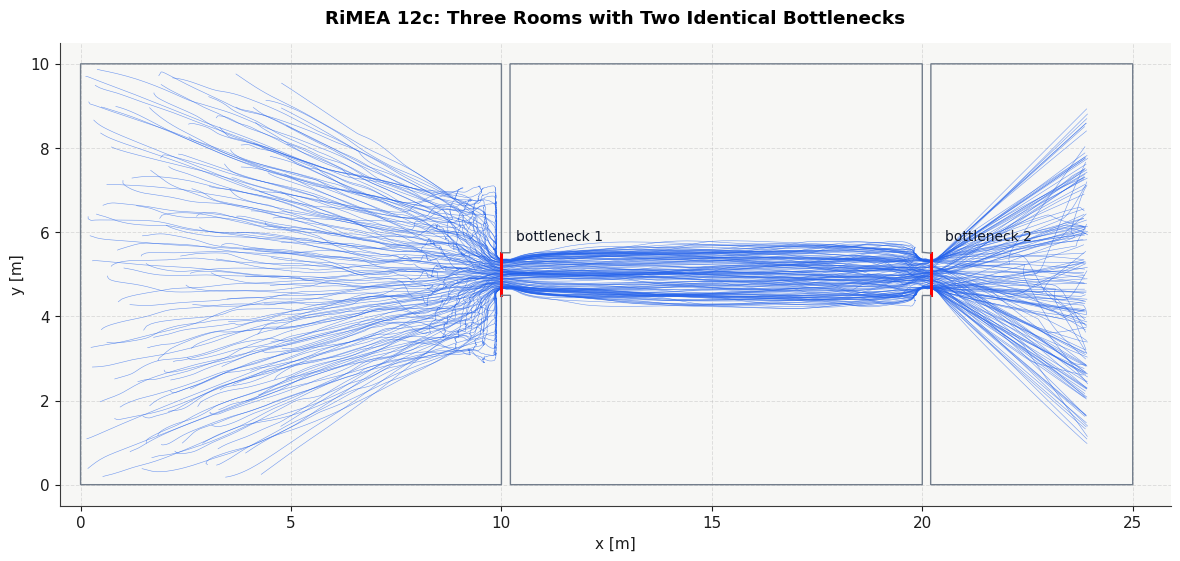

In [5]:
fig, ax = plt.subplots(figsize=(14, 5.5), constrained_layout=True)
pedpy.plot_measurement_setup(
    traj=traj,
    walkable_area=walkable_area,
    measurement_lines=BOTTLENECK_LINES,
    axes=ax,
    traj_alpha=0.65,
    traj_width=0.4,
    ml_width=2.2,
    ml_alpha=0.25,
    traj_color="#2563EB",
    ml_color="red",
).set_aspect("equal")
ax.text(10.35, 5.8, "bottleneck 1", fontsize=10, color="#111827")
ax.text(20.55, 5.8, "bottleneck 2", fontsize=10, color="#111827")
ax.set_title("RiMEA 12c: Three Rooms with Two Identical Bottlenecks", pad=14)
ax.set_xlim(-0.5, 25.9)
ax.set_ylim(-0.5, 10.5)
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.show()

## Agents per Room over Time

Rooms are defined by the x ranges of the geometry. The two bottlenecks are 0.2 m deep; agents inside them are counted in their own bottleneck bucket so that the sum is complete. Agents that have left the geometry are counted as evacuated.

In [6]:
X_EDGES = (10.0, 10.2, 20.2, 20.4)
BUCKETS = ("room 1", "bottleneck 1", "room 2", "bottleneck 2", "room 3")
total = int(result.metrics["total_agents"])

data = traj.data
frames = np.sort(data["frame"].unique())
last_frame = data.groupby("id")["frame"].max()
bucket = np.searchsorted(X_EDGES, data["x"].to_numpy(), side="right")
counts = np.zeros((len(frames), len(BUCKETS)), dtype=int)
np.add.at(counts, (np.searchsorted(frames, data["frame"].to_numpy()), bucket), 1)
evacuated = np.array([(last_frame < f).sum() for f in frames])
time = frames / traj.frame_rate
residual = np.abs(counts.sum(axis=1) + evacuated - total)

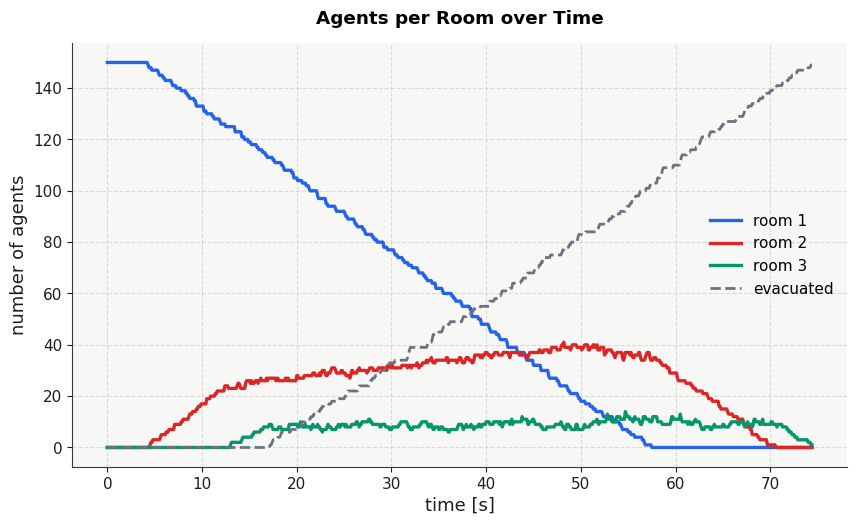

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(time, counts[:, 0], color="#2563EB", linewidth=2.4, label="room 1")
ax.plot(time, counts[:, 2], color="#DC2626", linewidth=2.4, label="room 2")
ax.plot(time, counts[:, 4], color="#059669", linewidth=2.4, label="room 3")
ax.plot(time, evacuated, color="#6B7280", linewidth=2.0, linestyle="--", label="evacuated")
ax.set_title("Agents per Room over Time", pad=14)
ax.set_xlabel("time [s]", fontsize=13)
ax.set_ylabel("number of agents", fontsize=13)
ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="center right")
plt.show()

## Cumulative Crossings and Flows

The flow through a bottleneck is (N - 1) / (t_last - t_first) of the first crossings of its measurement line. The specific flow divides by the 1 m width.

In [8]:
def first_crossings(line):
    _, crossing = pedpy.compute_n_t(traj_data=traj, measurement_line=line)
    return np.sort(crossing.groupby("id")["frame"].min().to_numpy()) / traj.frame_rate


cross = [first_crossings(line) for line in BOTTLENECK_LINES]
flows = [(len(t) - 1) / (t[-1] - t[0]) for t in cross]
WIDTH = 1.0

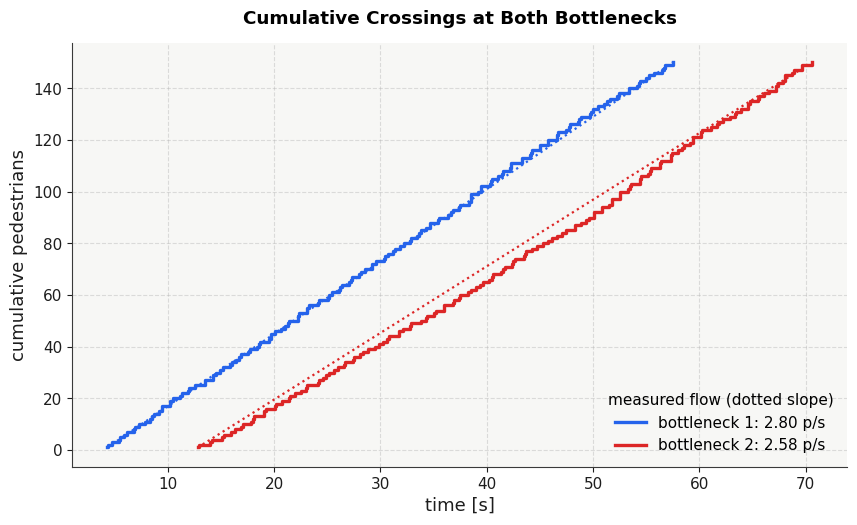

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (t, color) in enumerate(zip(cross, ["#2563EB", "#DC2626"])):
    ax.step(t, np.arange(1, len(t) + 1), where="post", color=color, linewidth=2.4,
            label=f"bottleneck {i + 1}: {flows[i]:.2f} p/s")
    ax.plot([t[0], t[-1]], [1, len(t)], color=color, linestyle=":", linewidth=1.6)
ax.set_title("Cumulative Crossings at Both Bottlenecks", pad=14)
ax.set_xlabel("time [s]", fontsize=13)
ax.set_ylabel("cumulative pedestrians", fontsize=13)
ax.grid(True, linestyle="--", linewidth=0.8, alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(frameon=False, loc="lower right", title="measured flow (dotted slope)")
plt.show()

## Acceptance

RiMEA sets no criterion for this test. Only conservation of agents is asserted; the flows and the room 2 peak are reported.

In [10]:
assert total == 150
assert residual.max() == 0, f"conservation violated, max residual {residual.max()}"
for i, flow in enumerate(flows):
    print(f"bottleneck {i + 1}: {flow:.3f} p/s ({flow / WIDTH:.3f} p/(m s))")
print(f"peak agents in room 2: {counts[:, 2].max()}")
print(f"max conservation residual: {residual.max()}")

bottleneck 1: 2.801 p/s (2.801 p/(m s))
bottleneck 2: 2.578 p/s (2.578 p/(m s))
peak agents in room 2: 41
max conservation residual: 0


## Clean Up

In [11]:
result.cleanup()

1